# Random Forest summary

Alex Koiter

## Load libraries

In [ ]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
  library(gt)
  library(tidytext)
})


## Importance

In [ ]:
imp_data <- read_csv(here::here("./notebooks/importance_data_49.csv")) %>%
  rename("Terrain Attribute" = "Var.Names") %>%
  mutate(`Terrain Attribute` = fct_recode(`Terrain Attribute`, "Elevation" = "elevation", 
                                          "Catchment Area" = "catchment_area",
                                          "Plan Curvature" = "plan_curvature",
                                          "Profile Curvature" = "profile_curvature",
                                          "Rel. Slope Position" = "relative_slope_position",
                                          "SAGA Wetness Index" = "saga_wetness_index",
                                          "Vert. Dist. Channel" = "channel_network_distance")) %>%
  mutate(`Terrain Attribute` = fct_relevel(`Terrain Attribute`, "Elevation", "SAGA Wetness Index", "Rel. Slope Position", "Vert. Dist. Channel","Catchment Area", "Profile Curvature", "Plan Curvature")) %>%
  mutate(property = fct_recode(property, "italic(`a*`)" = "a_col", "italic(`b*`)" = "b_col", "italic(`c*`)" = "c_col", "italic(`h*`)" = "h_col", "italic(`x`)" = "x_col")) %>%
  mutate(property = fct_relevel(property, "Ca", "Co", "Cs", "Fe", "Li", "La", "Nb", "Ni", "Rb", "Sr", "italic(`a*`)", "italic(`b*`)", "italic(`c*`)", "italic(`h*`)", "italic(`x`)"))


Rows: 161 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): Var.Names, site, property
dbl (4): %IncMSE, IncNodePurity, MSE_rank, Purity_rank

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Terrain Attribute and site.
ℹ Output is grouped by Terrain Attribute.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Terrain Attribute, site))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.

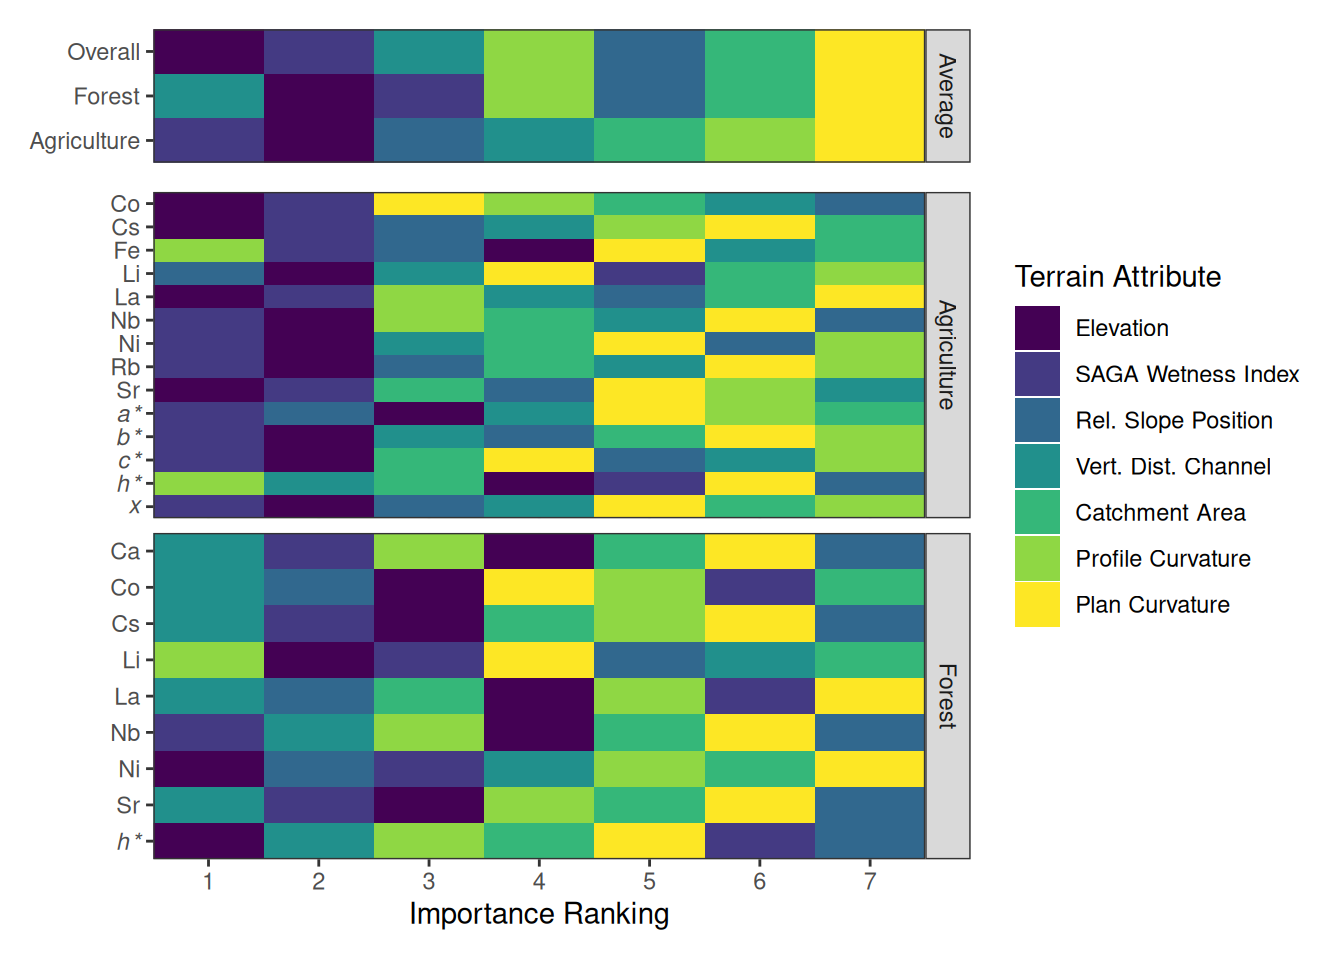

In [ ]:

p <- g2 + g1 + plot_layout(ncol = 1, heights = c(2, 10), guides = "collect") & theme(legend.position = 'right')
p
# ggsave(filename = "./Submission/Figure 4.png", plot = p, height = 130, width = 140, units = "mm", dpi = 600)


ℹ Please use `linewidth` instead.

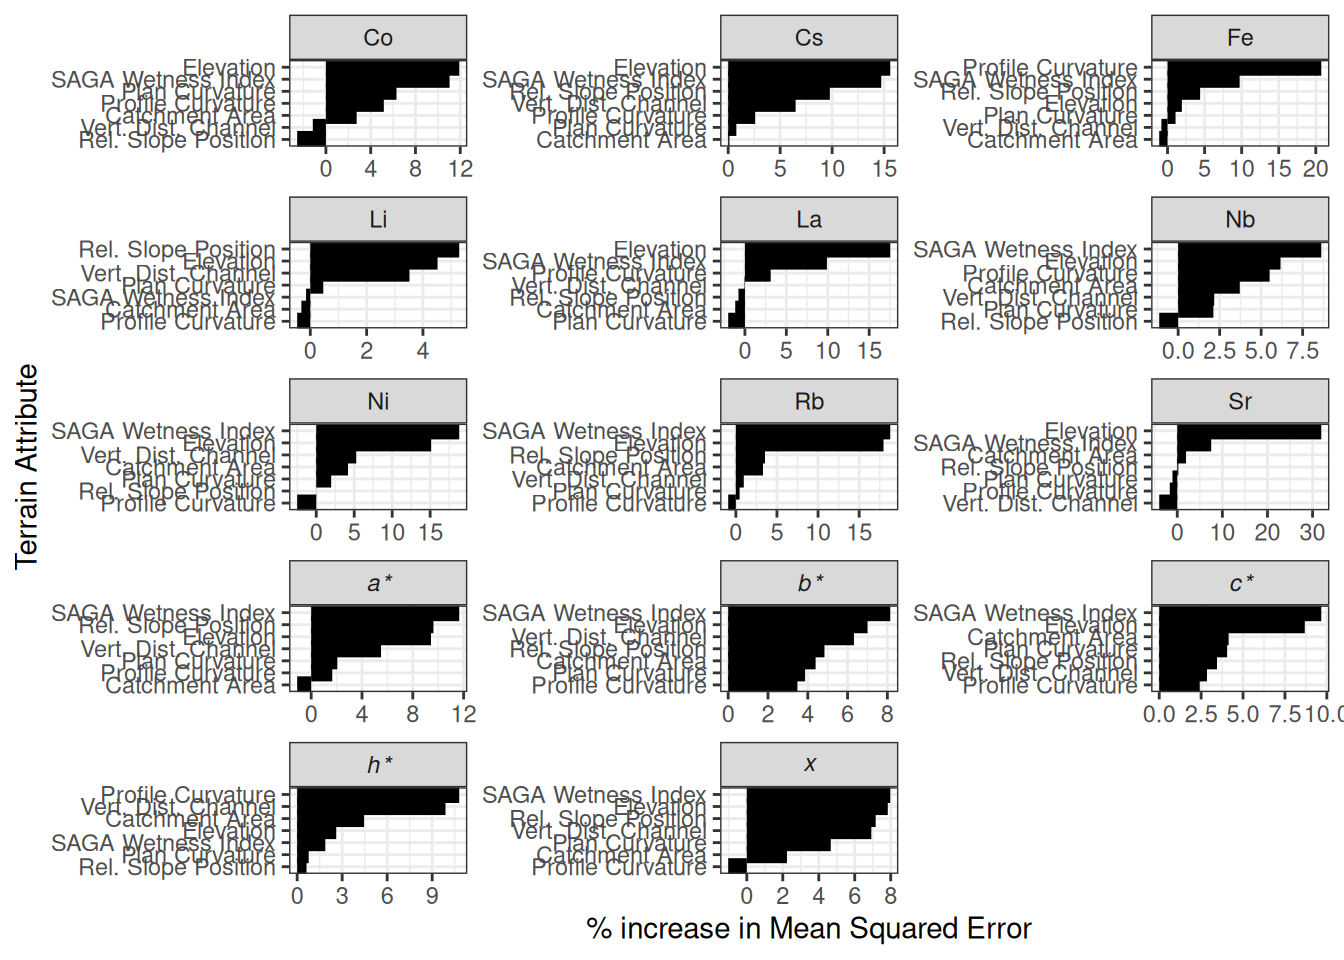

In [ ]:
# Reorder Terrain Attribute within each property by %IncMSE
ag_imp_data_filtered <- filter(imp_data, site == "Agriculture") %>%
  mutate(`Terrain Attribute` = reorder_within(`Terrain Attribute`, `%IncMSE`, property))

# Create the plot with properly ordered x-axis in each facet
ag_imp_data <- ggplot(ag_imp_data_filtered, aes(x = `Terrain Attribute`, y = `%IncMSE`)) +
  geom_segment(aes(x = `Terrain Attribute`, xend = `Terrain Attribute`, y = 0, yend = `%IncMSE`), color = "black", size = 3) +
  theme_bw() +
  coord_flip() +
  labs(x = "Terrain Attribute", y = "% increase in Mean Squared Error") +
  theme(legend.position = "bottom") +
  facet_wrap(~ property, scales = "free", labeller = label_parsed, ncol = 3) +
  scale_x_reordered()  # Applies correct labels after reorder_within


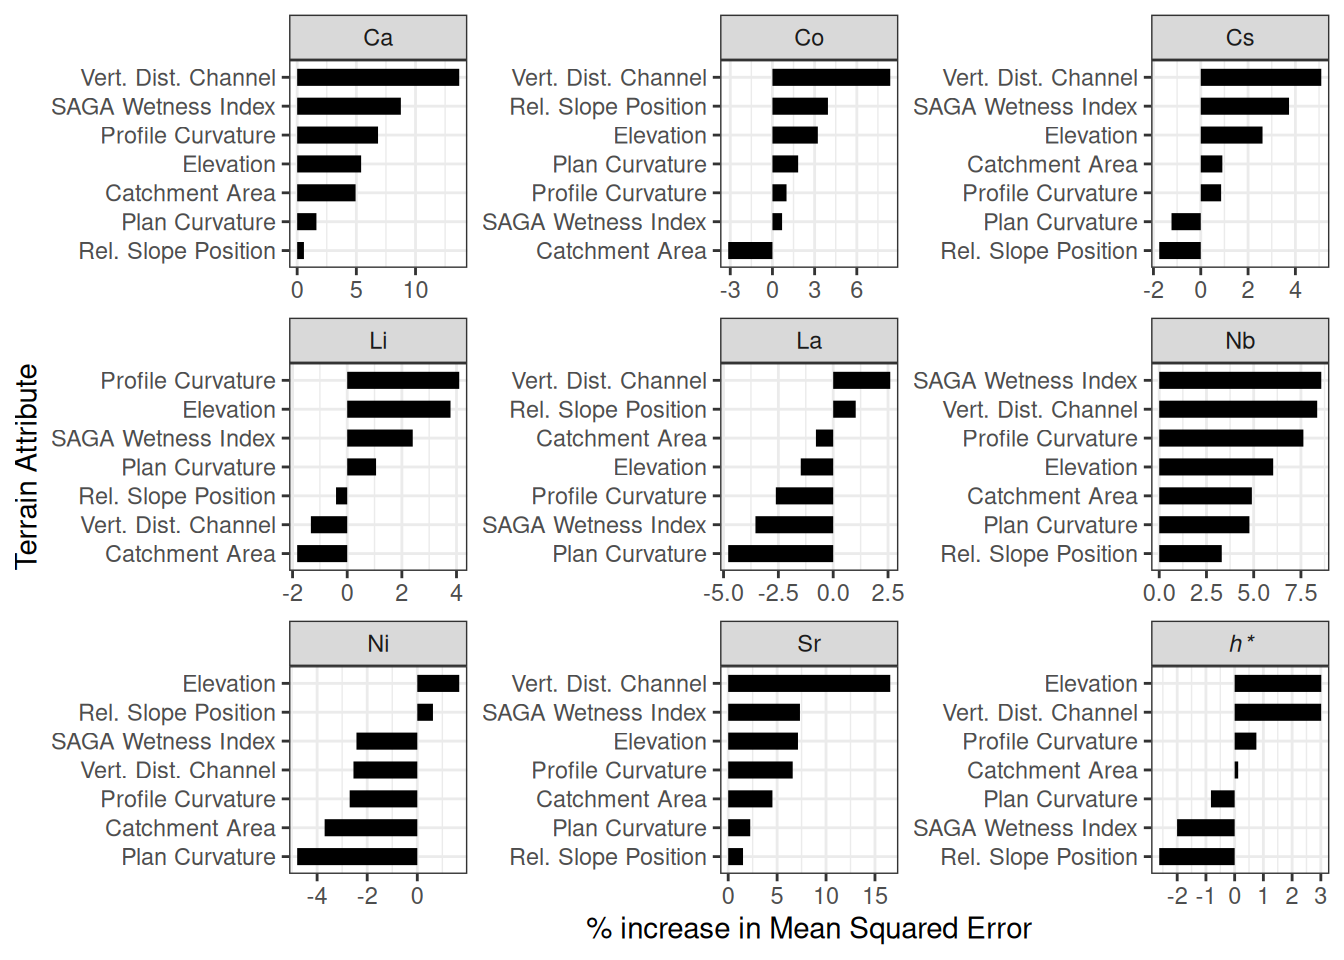

In [ ]:
forest_imp_data_filtered <- filter(imp_data, site == "Forest") %>%
  mutate(`Terrain Attribute` = reorder_within(`Terrain Attribute`, `%IncMSE`, property))

forest_imp_data <- ggplot(forest_imp_data_filtered, aes(x = `Terrain Attribute`, y = `%IncMSE`)) +
  geom_segment(aes(x = `Terrain Attribute`, xend = `Terrain Attribute`, y = 0, yend = `%IncMSE`), color = "black", size = 3) +
  theme_bw() +
  coord_flip() +
  labs(x = "Terrain Attribute", y = "% increase in Mean Squared Error") +
  theme(legend.position = "bottom") +
  facet_wrap(~ property, scales = "free", labeller = label_parsed) +
  scale_x_reordered()  # Applies correct labels after reorder_within
forest_imp_data


## Performance

In [ ]:
m_performance_2 <- read_csv(here::here("./notebooks/model_performance_data_2.csv")) |>
  mutate(property = fct_recode(property, "a*" = "a_col", "b*" = "b_col", "c*" = "c_col", "h*" = "h_col", "x" = "x_col")) |>
  mutate(property = fct_relevel(property, "Ca", "Co", "Cs", "Fe", "Li", "La", "Nb", "Ni", "Rb", "Sr", "a*", "b*", "c*", "h*", "x"))


Rows: 23 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): MSE_test, R2_test, site, property
dbl (1): stability

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

Rows: 23 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): site, property
dbl (4): MSE, Var_exp, R2, mse_test

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Joining with `by = join_by(site, property)`

In [ ]:

m_performance |>
  group_by(site) |>
  gt() |>
  tab_spanner(label = "Training",
               columns = c(Var_exp, MSE_org, stability)) |>
  tab_spanner(label = "Test",
              columns = c(R2_test, MSE_test)) |>
  cols_move_to_start(columns = property) |>
  fmt_number(columns = c("MSE_org"), decimal = 2) |>
  fmt_number(columns = c("Var_exp"), decimal = 1) |>
  #fmt_number(columns = c("R2_org"), decimal = 2) |>
  tab_style(style =  cell_text(weight = "bold", align = "center"), locations =  cells_row_groups()) |>
  tab_style(style =  cell_text(align = "left"), locations =  cells_body()) |>
  tab_style(style =  cell_text(weight = "bold", align = "left"), locations =  cells_column_labels()) |>
  cols_label(Var_exp = "% Variance", MSE_org = "MSE", R2_test = "{{r^2}}", property = "Property", MSE_test = "MSE", stability = "VI Satability") |>
  row_group_order(groups = c("Agriculture", "Forest"))  |>
  tab_style(
    style = list(cell_text(style = "italic")),
    locations = cells_body(
      columns = property,
      rows = property %in% c("a*", "b*", "c*", "h*", "x"))) |>
    opt_footnote_marks(marks = "standard") |>
    tab_footnote(
    footnote = "Mean square error",
    locations = cells_column_labels(columns = c("MSE_org"))) |>
    tab_footnote(
    footnote = "Mean square error and 95% Confidence Intervals",
    locations = cells_column_labels(columns = c("MSE_test"))) |>
  tab_footnote(
    footnote = "Percent variance explained",
    locations = cells_column_labels(columns = c("Var_exp"))) |>
  tab_footnote(
    footnote = html("r<sup>2</sup> and 95% Confidence Intervals"),
    locations = cells_column_labels(columns = c("R2_test"))) |>
    tab_footnote(
    footnote = "Varible Importance Stability",
    locations = cells_column_labels(columns = c("stability"))) 


Property 
 
 Training 
 
 
 Test 
 
 
 
 % Variance * 
 MSE † 
 VI Satability ‡ 
 r 2 § 
 MSE ** 
 
 
 
 
 Agriculture 
 
 Co 
 33.2 
 0.43 
 0.98 
 0.11 (0, 0.52) 
 0.52 (0.18, 1) 
 Cs 
 57.4 
 0.01 
 0.99 
 0.29 (0.03, 0.64) 
 0.01 (0.01, 0.02) 
 Fe 
 34.4 
 0.01 
 0.99 
 0.01 (0, 0.43) 
 0.01 (0.01, 0.01) 
 Li 
 −14.9 
 1.86 
 0.85 
 0.43 (0.24, 0.71) 
 0.84 (0.35, 1.54) 
 La 
 37.4 
 0.39 
 0.99 
 0.81 (0.57, 0.92) 
 0.38 (0.22, 0.56) 
 Nb 
 17.2 
 0.00 
 0.95 
 0 (0, 0.31) 
 0 (0, 0.01) 
 Ni 
 65.1 
 1.89 
 0.99 
 0.7 (0.48, 0.88) 
 1.49 (0.62, 2.65) 
 Rb 
 76.1 
 3.75 
 1.00 
 0.85 (0.73, 0.95) 
 2.73 (1.19, 4.56) 
 Sr 
 64.4 
 441.33 
 1.00 
 0.85 (0.75, 0.94) 
 370.87 (131.19, 657.81) 
 a* 
 41.5 
 0.03 
 0.97 
 0.48 (0.22, 0.79) 
 0.02 (0.01, 0.04) 
 b* 
 31.8 
 0.53 
 0.90 
 0.09 (0, 0.5) 
 0.41 (0.12, 0.84) 
 c* 
 29.2 
 0.64 
 0.93 
 0.1 (0, 0.51) 
 0.5 (0.14, 1.03) 
 h* 
 20.2 
 0.00 
 0.94 
 0.03 (0, 0.42) 
 0 (0, 0) 
 x 
 34.5 
 0.00 
 0.96 
 0.31 (0.02, 0.67) 
 0 (0, 0) 
 
 Forest 
 
 Ca 
 41.5 
 0.32 
 0.98 
 0.25 (0.01, 0.65) 
 0.58 (0.37, 0.82) 
 Co 
 −17.3 
 0.97 
 0.93 
 0.01 (0, 0.26) 
 1.03 (0.62, 1.53) 
 Cs 
 −5.6 
 0.01 
 0.90 
 0.02 (0, 0.51) 
 0.01 (0, 0.01) 
 Li 
 −8.1 
 0.55 
 0.61 
 0.05 (0, 0.39) 
 1.33 (0.66, 2.28) 
 La 
 −31.2 
 2.49 
 0.88 
 0.02 (0, 0.34) 
 3.76 (1.78, 5.86) 
 Nb 
 36.1 
 0.00 
 0.89 
 0.16 (0, 0.49) 
 0 (0, 0) 
 Ni 
 −43.7 
 7.78 
 0.76 
 0.02 (0, 0.4) 
 6.93 (3.83, 10.83) 
 Sr 
 40.1 
 44.47 
 0.98 
 0.17 (0, 0.6) 
 58.2 (31.76, 92.06) 
 h* 
 −13.7 
 0.00 
 0.75 
 0.01 (0, 0.47) 
 0 (0, 0) 
 
 
 
 * Percent variance explained 
 
 
 † Mean square error 
 
 
 ‡ Varible Importance Stability 
 
 
 § r 2 and 95% Confidence Intervals 
 
 
 ** Mean square error and 95% Confidence Intervals